## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---


In [83]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import os

import kagglehub

import warnings
warnings.filterwarnings("ignore")

In [2]:
### Visualization settings ##

##### Matplotlib ##
# Matplotlib inline to visualize Matplotlib graphs
%matplotlib inline

# Configuration to set so that all the Seaborn figures come out with this size
%config Inlinebackend.figure_format= 'retina'


#### Pandas ###
#### show the max of columns in a pandas object
pd.set_option('display.max_columns', None)

############ Seaborn ##
# Set the Seaborn context to "poster" for larger text and figures
sns.set_context("poster")

# Set the default figure size for Seaborn plots
sns.set(rc={"figure.figsize": (12., 6.)})

# Set the Seaborn style to "whitegrid" for a white background with gridlines
# sns.set_style("whitegrid")

In [3]:
##### Get the data from Kaggle ###
# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
# print("Path to dataset files:", path)

# List all files in the downloaded directory
files = os.listdir(path)
# print("Files in dataset:", files)

# Load the CSV file: Get first CSV file
csv_file = [f for f in files if f.endswith('.csv')][0]  
full_path = os.path.join(path, csv_file)
# print(f"Loading file: {full_path}")

In [4]:
# ============================================
# 1. LOAD AND PREPARE DATA
# ============================================
aws_products = pd.read_csv(full_path)

print(f"Total products: {len(aws_products):}")
print(f"Columns: {aws_products.columns.tolist()}")
print(f"\nFirst few rows:")
display(aws_products.head())

Total products: 2443651
Columns: ['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

First few rows:


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
num = aws_products.select_dtypes(include="number") 
cat = aws_products.select_dtypes(exclude="number")


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*



In [6]:
crosstab_Cat_isBestSeller = pd.crosstab(cat['category'], cat['isBestSeller'])
crosstab_Cat_isBestSeller

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [120]:
crosstab_Cat_isBestSeller_prop = pd.crosstab(cat['category'], cat['isBestSeller'], normalize='index').round(3)
crosstab_Cat_isBestSeller_prop

isBestSeller,False,True
category,,
3D Printers,0.996,0.004
3D Printing & Scanning,1.000,0.000
Abrasive & Finishing Products,0.980,0.020
Action Cameras,0.999,0.001
Adapters,0.988,0.012
...,...,...
Wind Instruments,0.972,0.028
Window Treatments,0.979,0.021
Women,0.988,0.012


In [ ]:
crosstab_Cat_isBestSeller_prop[
    crosstab_Cat_isBestSeller_prop.iloc[:, 1] > 0.5
]

isBestSeller,False,True
category,,


-- Insights
- There is no category where being a best-seller is more prevalent

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [ ]:
from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_Cat_isBestSeller)

float(chi2_pvalue) <= 0.05
# If the p value is smaller than 0.05 (or alpha) we do have a correlation between 2 categorical variables
# Else, nothigness

## H0 we dont have correlation between categorical values!!

True

In [ ]:
from scipy.stats.contingency import association
association(crosstab_Cat_isBestSeller, method='cramer') ## they are weakly associated

0.1222829439760564

-- Cramér’s V Interpretation Guide (Cohen's Conventions)

| Cramér’s V | Strength of Association   |
|------------|----------------------------|
| 0.00–0.10  | Negligible / Very Weak     |
| 0.10–0.20  | Weak                       |
| 0.20–0.30  | Moderate                   |
| 0.30–0.50  | Strong                     |
| > 0.50     | Very Strong                |


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

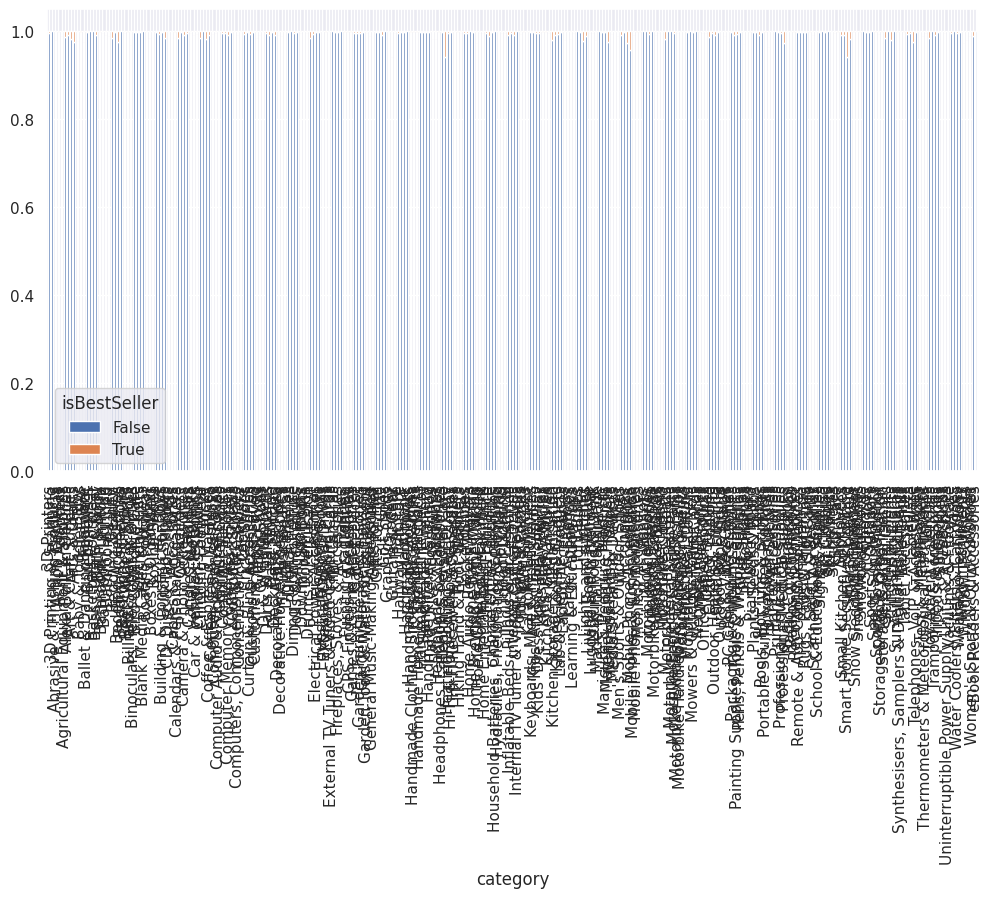

In [ ]:
# Plotting a stacked bar chart for the 'crosstab_Cat_isBestSeller' data
crosstab_Cat_isBestSeller_prop.plot(kind='bar', stacked=True)
plt.show()

<Axes: xlabel='category'>

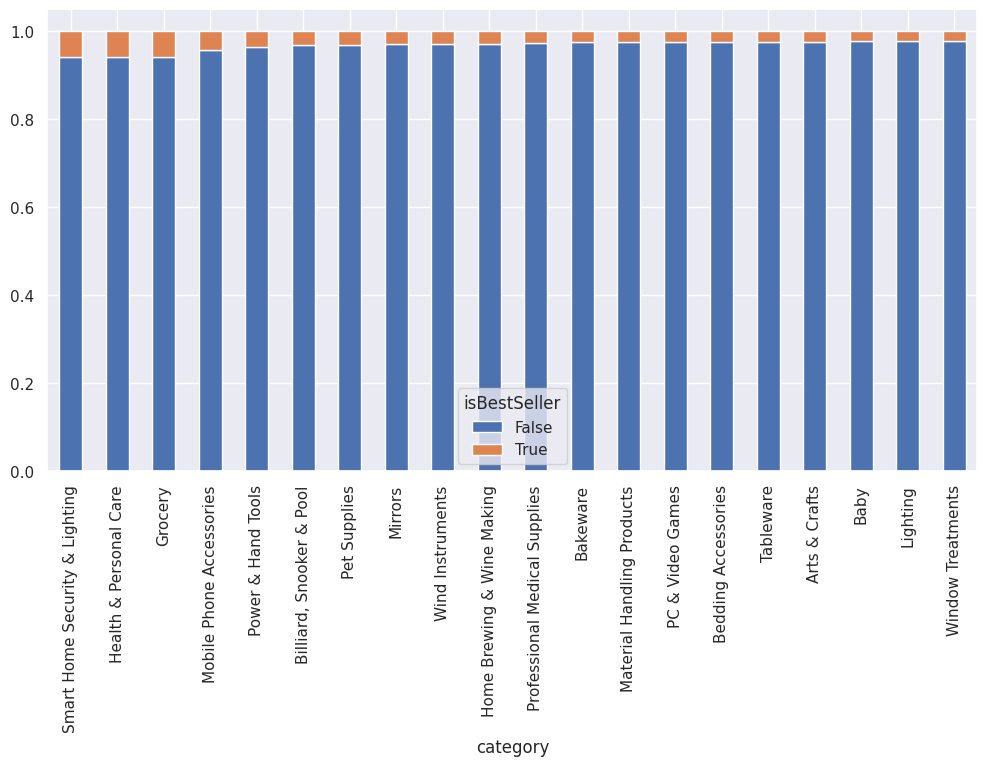

In [253]:
### Select the most frequent data with that are best-seller
n= 20
top_nBestSeller = crosstab_Cat_isBestSeller_prop.sort_values(by=True, ascending=False).head(n)
top_nBestSeller.plot(kind='bar', stacked=True) 

In [ ]:
### OR Select the 20 top frequent products
n = 20
top_nCategories = aws_products.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = aws_products[aws_products.category.isin(top_nCategories)]

<Axes: xlabel='category'>

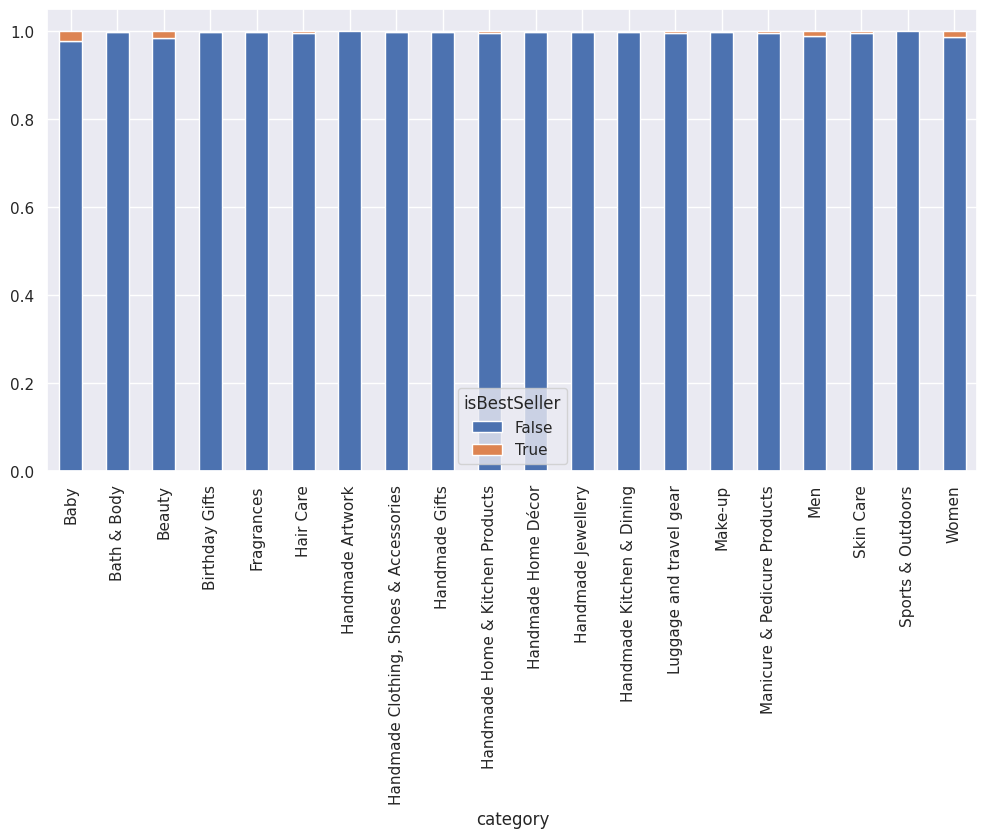

In [ ]:
#### Plot the proportion is better ##
pd.crosstab(aws_products_topn['category'], aws_products_topn['isBestSeller'], normalize='index').round(3).plot(kind='bar', stacked=True)
plt.show()

### **Insights**
- There is no category where being a best-seller is more prevalent
- We could confirm that category and IsBestSeller are weakly correlated first with the Chi-square score (p-value<0.5)
- When ploting the stacked bar plot with the proportions of best-seller by category 

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*





In [167]:
Q1_price = aws_products.price.quantile(0.25)
Q3_price = aws_products.price.quantile(0.75)
IQR_price = Q3_price - Q1_price

min_limit_price = float(Q1_price - 1.5*IQR_price)
max_limit_price = float(Q3_price + 1.5*IQR_price)


filtered_aws_products = aws_products[(aws_products.price > min_limit_price) & (aws_products.price < max_limit_price)]
filtered_aws_products

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.


In [ ]:
n = 20
top_nCategories = filtered_aws_products.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = filtered_aws_products[filtered_aws_products.category.isin(top_nCategories)]

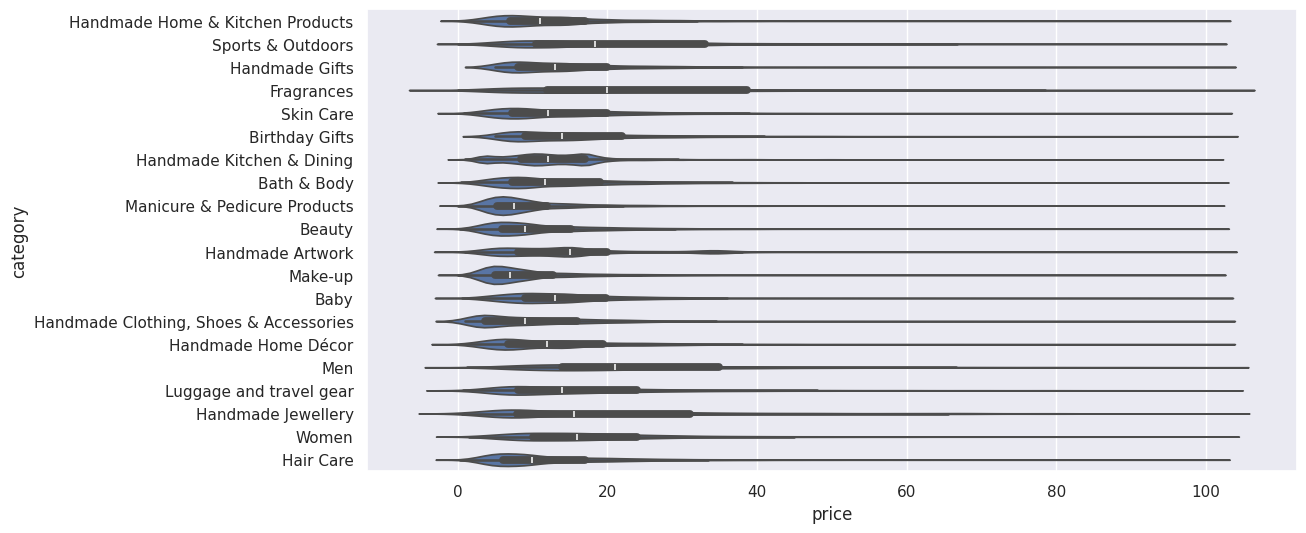

In [ ]:
sns.violinplot(data=aws_products_topn, x="price", y="category")

plt.tight_layout()       # Prevent label cutoff
plt.show()

In [ ]:
HighmedianPrice_cat = filtered_aws_products[['price', 'category']].groupby('category').agg('median').nlargest(1, columns='price')
HighmedianPrice_cat

### >> Desktop PCs category has the highest median price with filtered products !!

,price
category,
Desktop PCs,74.0


In [ ]:
HighmedianPrice_cat = aws_products[['price', 'category']].groupby('category').agg('median').nlargest(1, columns='price')
HighmedianPrice_cat

### >> Laptops category has the highest median price with no filtered products !!

,price
category,
Laptops,1042.725


-- Insights

- Eliminating the outliers and selecting the first top frequent products changes the insights on the prices by categorie
- We find that with the original data the laptop category has the highest prices in the data even tough they are not the most requently bought ptoducts
- Whereas when filtering out the outliers we have that Desktop category is the pricy category
- When selecting the top 20 frequent products we see from the violin plot that men products are the pricy ones
- From this analysis we can consider binning the data into frequently/daily purchased products and long-term products


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.



In [193]:
n = 10
top_nCategories = filtered_aws_products.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = filtered_aws_products[filtered_aws_products.category.isin(top_nCategories)]

<Axes: xlabel='category'>

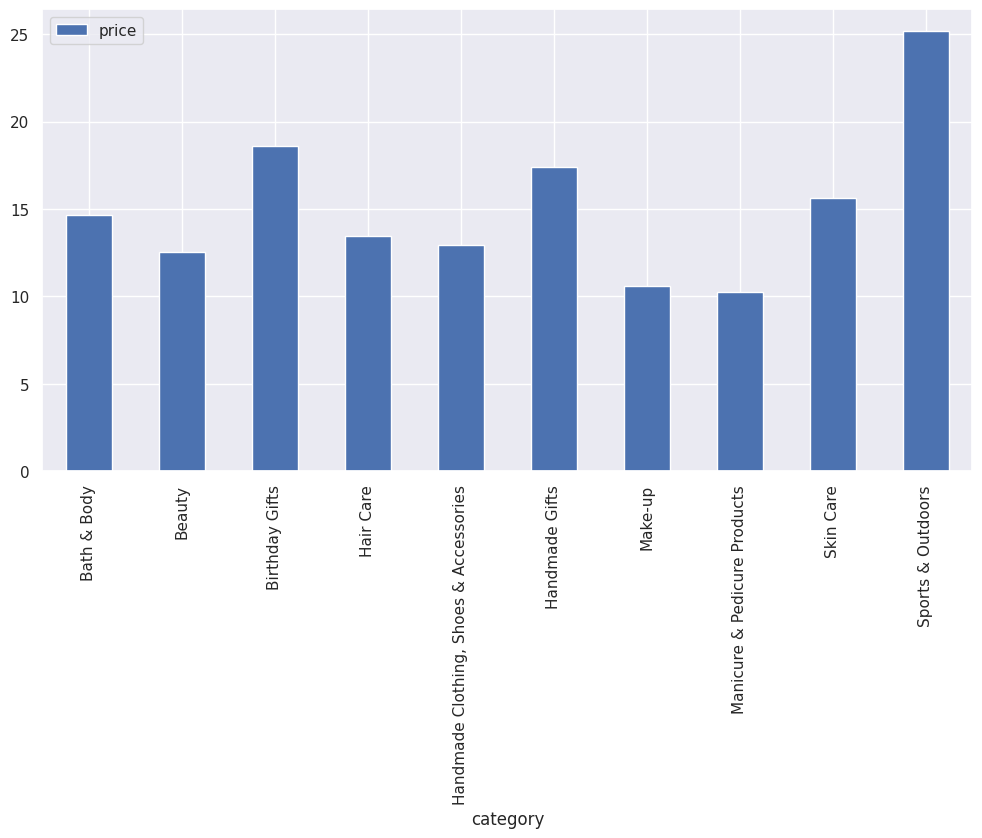

In [ ]:
avg_price_10top = aws_products_topn[['category', 'price']].groupby('category').agg('mean')
avg_price_10top.plot(kind='bar') ##, stacked=False

plt.tight_layout()       # Prevent label cutoff
plt.show()

In [190]:
HighavgPrice_cat = filtered_aws_products[['price', 'category']].groupby('category').agg('mean').nlargest(1, columns='price')
HighavgPrice_cat

,price
category,
Motherboards,68.772432


In [191]:
HighavgPrice_cat = aws_products[['price', 'category']].groupby('category').agg('mean').nlargest(1, columns='price')
HighavgPrice_cat

,price
category,
Laptops,1087.987827


-- Insights

- Eliminating the outliers and selecting the first top frequent products changes the insights on the prices by categorie
- We find that with the original data the laptop category has the highest prices in the data even tough they are not the most requently bought products. >> The average value is close to the median values for this category
- Whereas when filtering out the outliers we have that Motherboards category has the highest average price. The hoghest average price is different from the highest meadian prices!!
- When selecting the top 10 frequent products we see from the bar plot that sports and outdoors products are the pricy ones

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

In [ ]:
##### Filter out the raw with no ratings
filtered_aws_products_withRatings = filtered_aws_products[filtered_aws_products.stars != float(0)]
filtered_aws_products_withRatings

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443639,2828580,B09GLMT9ML,Scoyco 2pcs Motorcycle Knee Pads Gear Knee Gua...,3.6,25,49.99,False,0,Motorbike Clothing
2443642,2828585,B07DCFQMQL,Speed MaxX BODY ARMOUR CE MOTORBIKE/MOTORCYCLE...,3.6,66,49.99,False,0,Motorbike Clothing
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [204]:
n = 10
top_nCategories = filtered_aws_products_withRatings.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = filtered_aws_products_withRatings[filtered_aws_products_withRatings.category.isin(top_nCategories)]

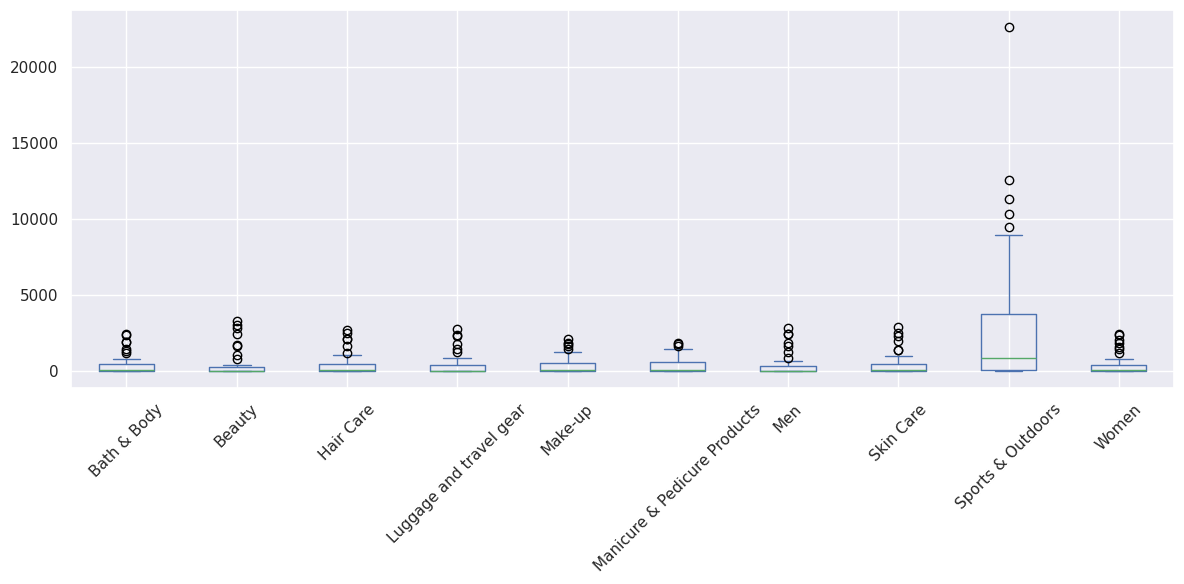

In [ ]:
pd.crosstab(aws_products_topn.stars, aws_products_topn.category).plot(kind='box')

plt.xticks(rotation=45)  # Rotate x-axis labels
plt.tight_layout()       # Prevent label cutoff
plt.show()

### **Insights**
- Eliminating the outliers and selecting the first top frequent products changes the insights on the prices by categorie
- We find that with the original data the laptop category has the highest prices in the data even tough they are not the most requently bought ptoducts
- Whereas when filtering out the outliers we have that Desktop category is the pricy category
- When selecting the top 20 frequent products we see from the violin plot that men products are the pricy ones
- From this analysis we can consider binning the data into frequently/daily purchased products and long-term products



- Eliminating the outliers and selecting the first top frequent products changes the insights on the prices by categorie
- We find that with the original data the laptop category has the highest prices in the data even tough they are not the most requently bought products. >> The average value is close to the median values for this category
- Whereas when filtering out the outliers we have that Motherboards category has the highest average price. The hoghest average price is different from the highest meadian prices!!
- When selecting the top 10 frequent products we see from the bar plot that sports and outdoors products are the pricy ones

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [ ]:
filtered_aws_products_star = filtered_aws_products[(filtered_aws_products.stars != 0.0)]
filtered_aws_products_star

In [263]:
# Calculating the Pearson correlation coefficient between 'stars' and 'price' columns
print(round(float(filtered_aws_products_star["price"].corr(filtered_aws_products_star["stars"], method="pearson")), 2))

# Calculating the Spearman correlation coefficient between 'stars' and 'price' columns
print(round(float(filtered_aws_products_star["price"].corr(filtered_aws_products_star["stars"], method="spearman")), 2))

0.01
0.02


2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---




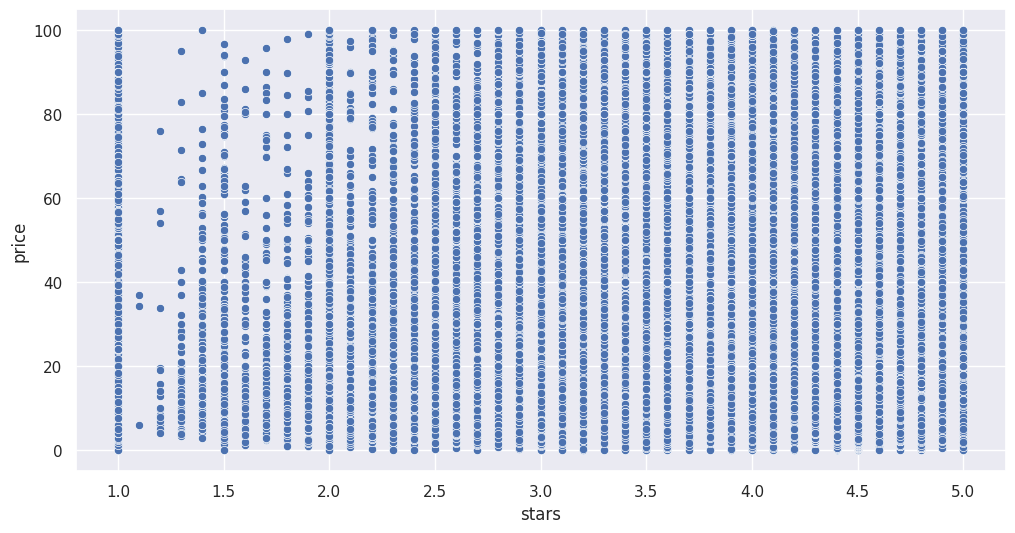

In [264]:
sns.scatterplot(x=filtered_aws_products_star.stars, y=filtered_aws_products_star.price)
plt.show()

In [265]:
filtered_num = filtered_aws_products_star.select_dtypes(include="number") 
filtered_cat = filtered_aws_products_star.select_dtypes(exclude="number")

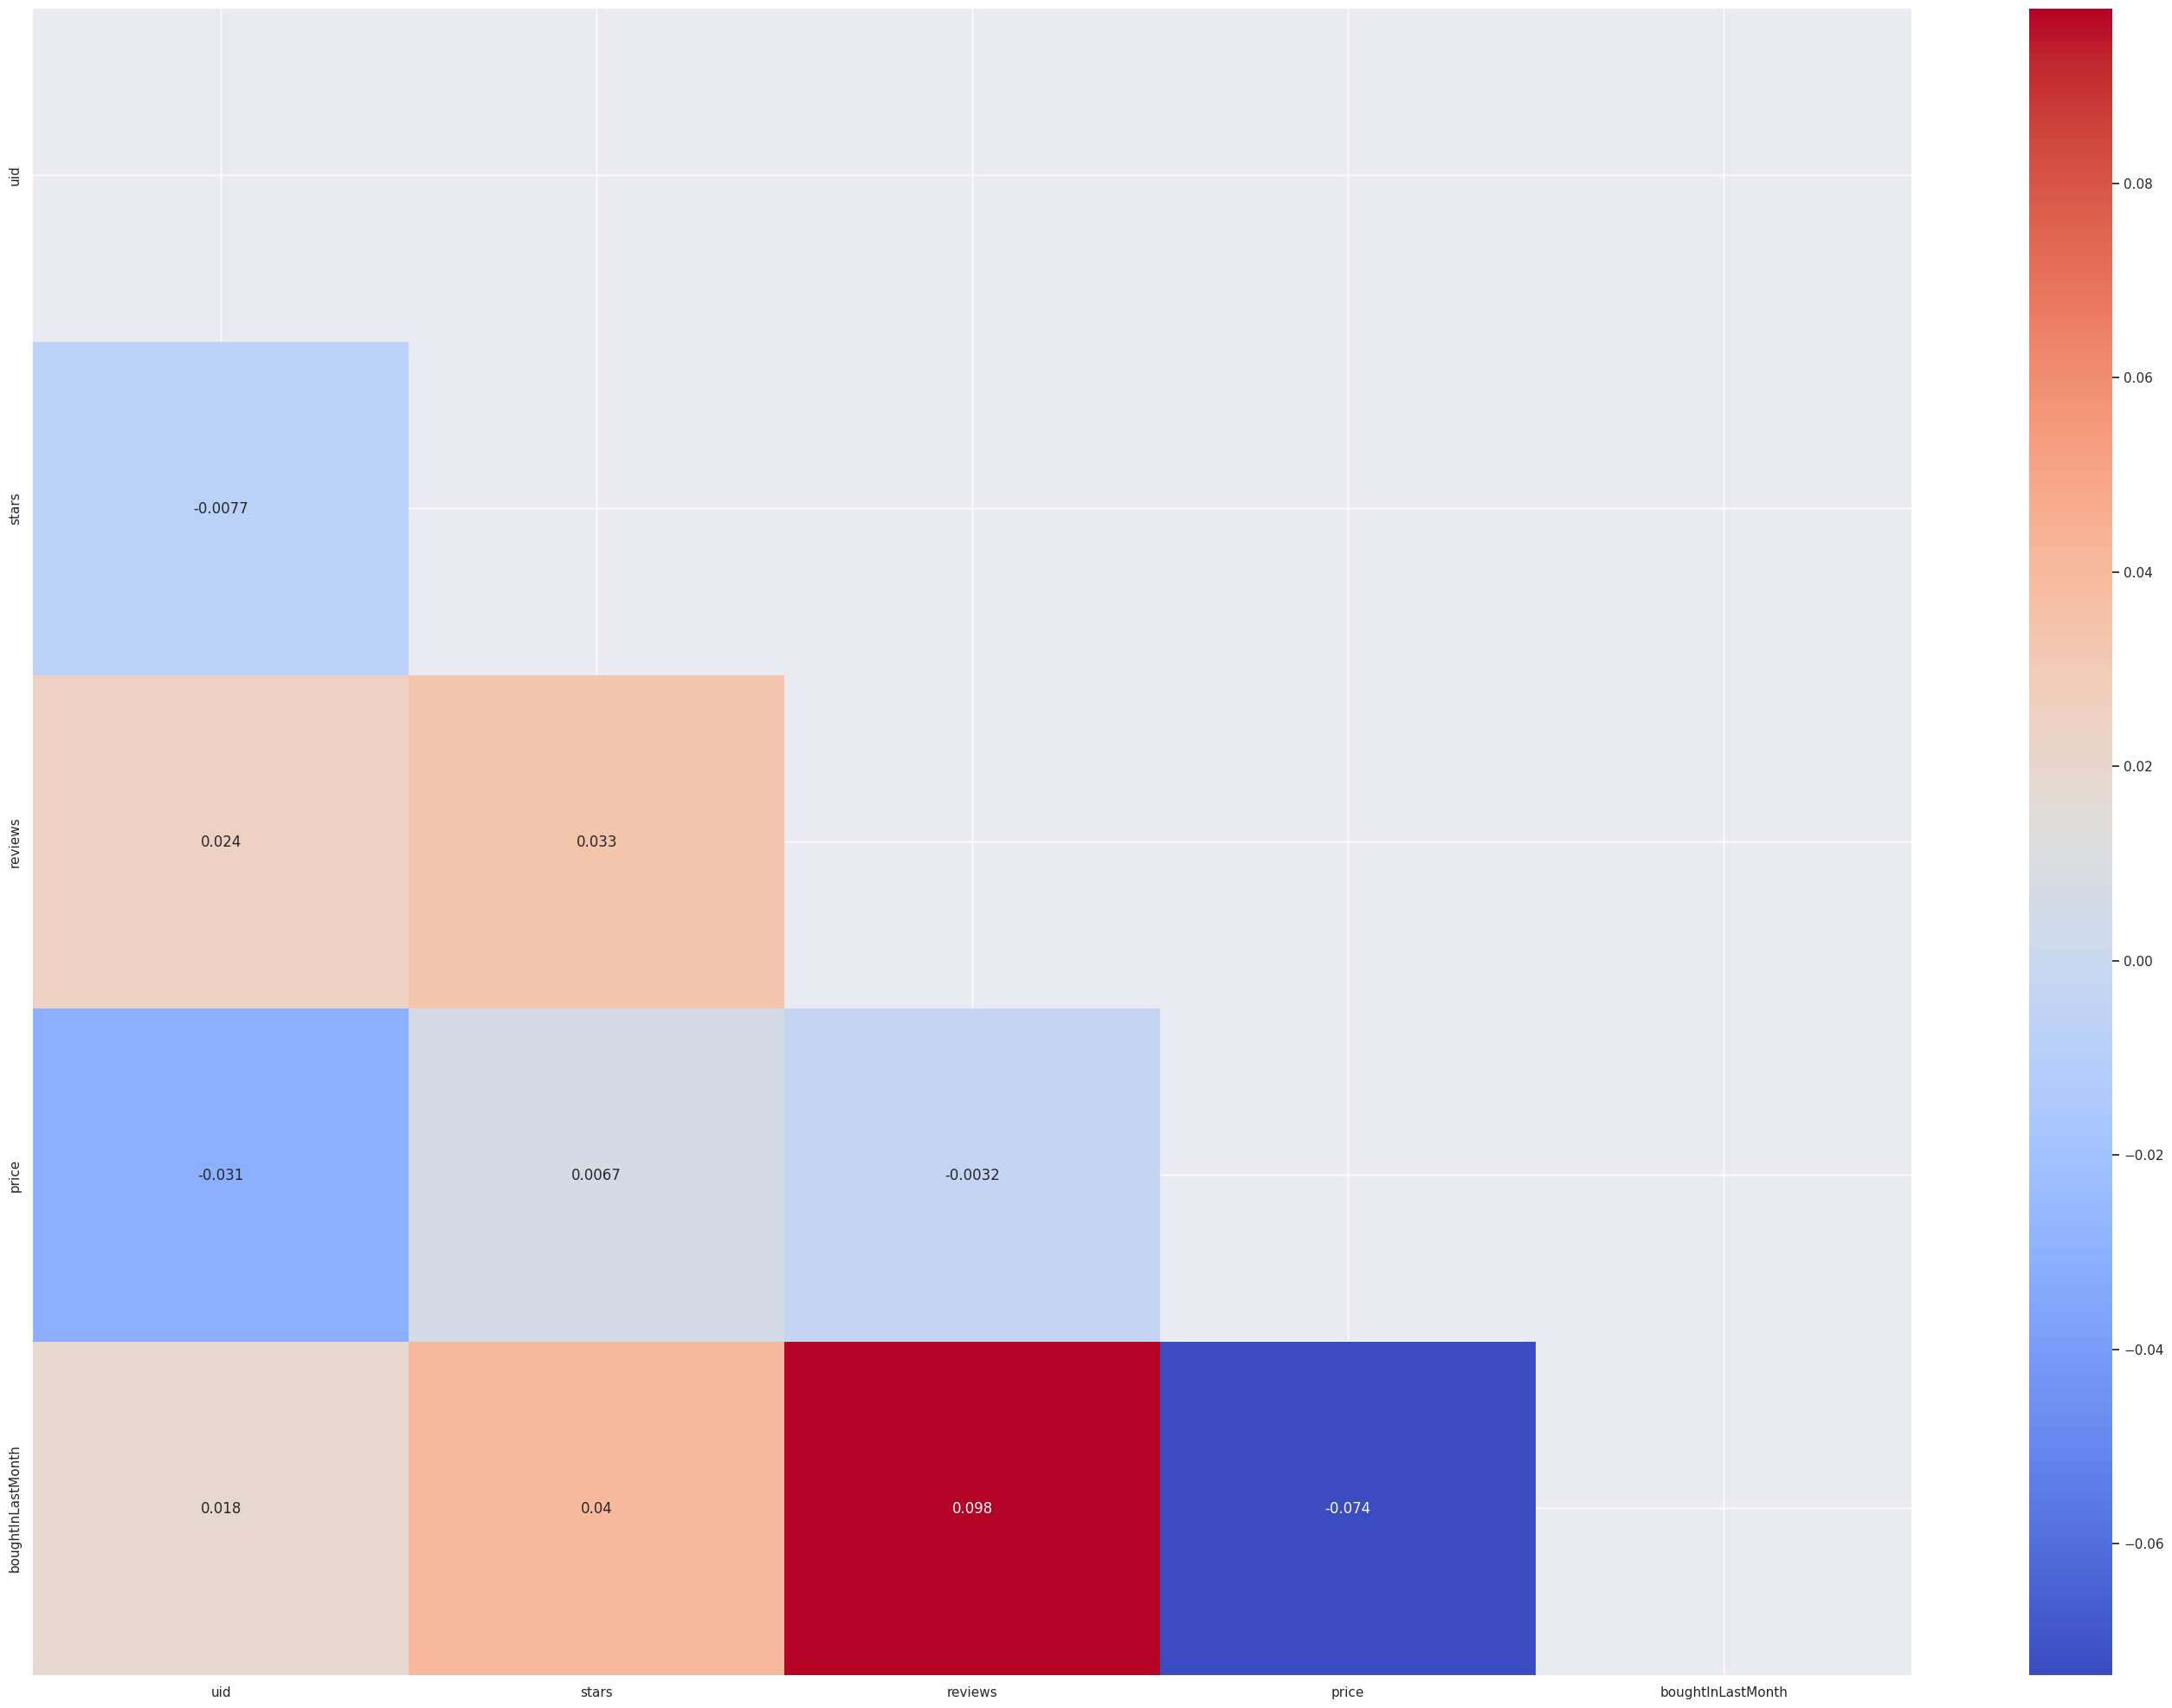

In [274]:
correlation_matrix = filtered_num.corr(method="pearson")

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(35, 25))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.show()

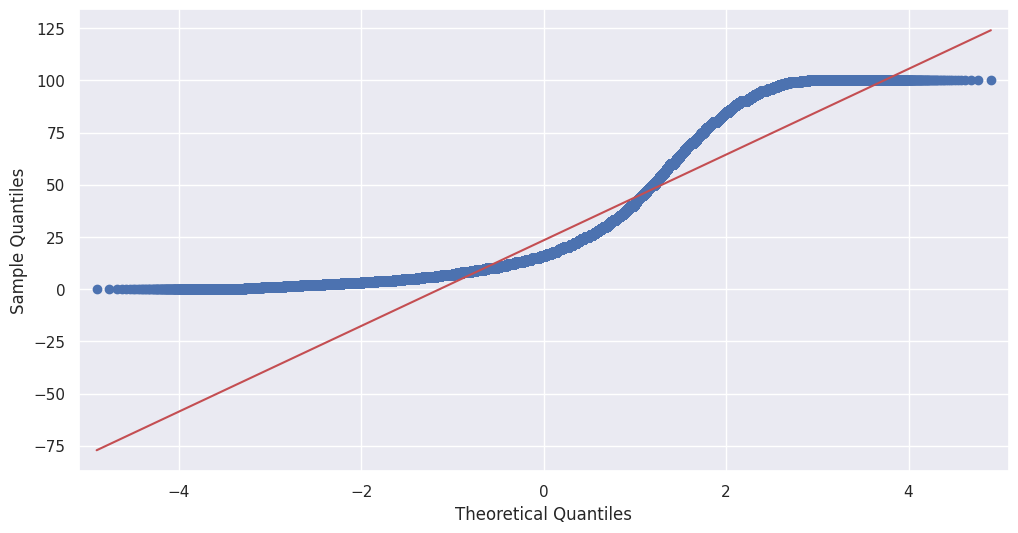

In [271]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(filtered_aws_products['price'], line='s')
plt.show()

### **Insights**
- No correlation between price and stars (coefficients of correlation close to zero)
- All numerical values are not correlating with each other
- The price values do not follow a normal distribution

### **Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

#### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*





1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.


In [90]:
n = 20
top_nCategories = aws_products.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = aws_products[aws_products.category.isin(top_nCategories)]

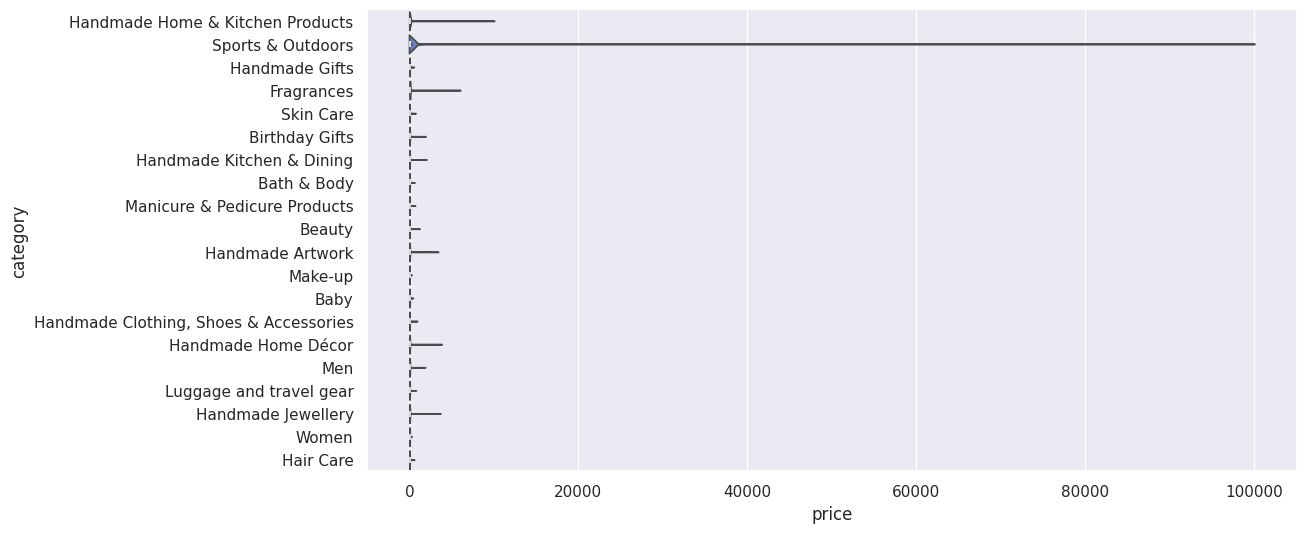

In [91]:
sns.violinplot(data=aws_products_topn, x="price", y="category", palette="coolwarm")
plt.show()


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.



In [92]:
n = 10
top_nCategories = aws_products.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = aws_products[aws_products.category.isin(top_nCategories)]

<Axes: xlabel='category'>

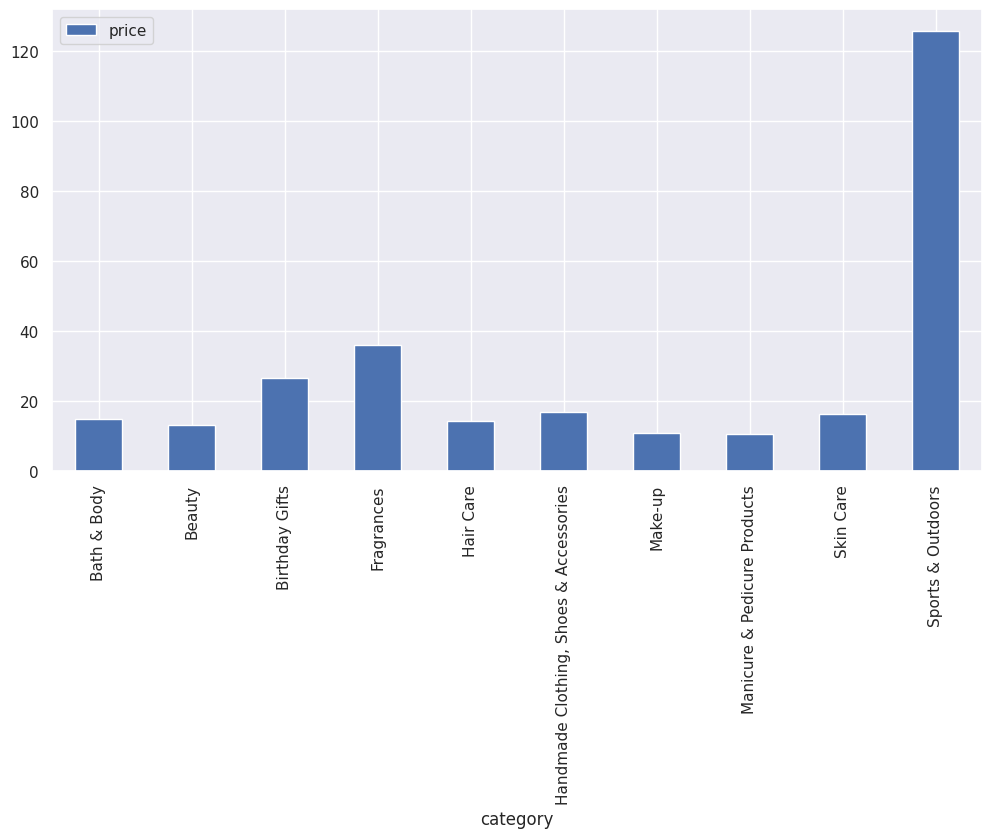

In [93]:
avg_price_10top = aws_products_topn[['category', 'price']].groupby('category').agg('mean')
avg_price_10top.plot(kind='bar') ##, stacked=False

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

In [94]:
n = 5
top_nCategories = aws_products.category.value_counts().nlargest(n).reset_index().category.tolist()
aws_products_topn = aws_products[aws_products.category.isin(top_nCategories)]

<Axes: >

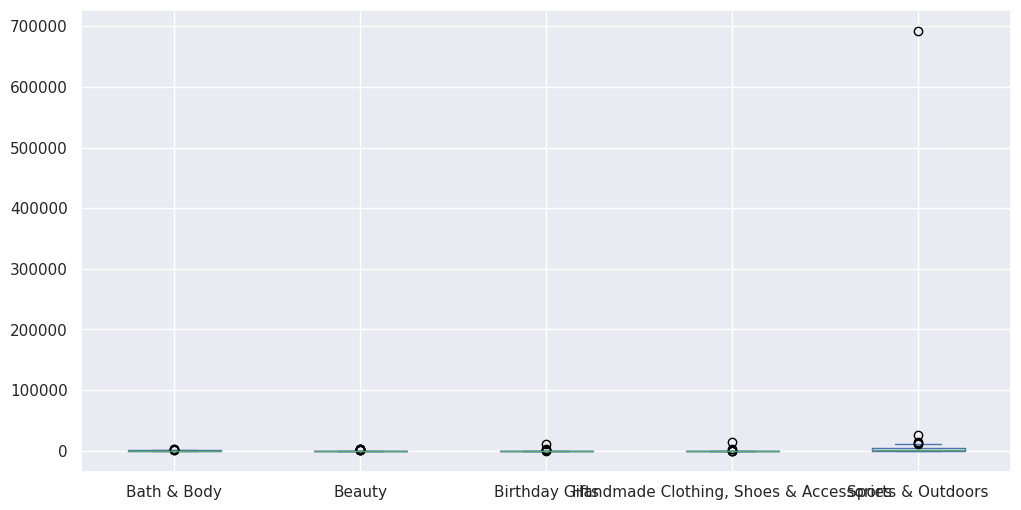

In [95]:
pd.crosstab(aws_products_topn.stars, aws_products_topn.category).plot(kind='box')

#### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [96]:
# Calculating the Pearson correlation coefficient between 'SalePrice' and 'GrLivArea' columns
round(float(aws_products["price"].corr(aws_products["stars"], method="pearson")), 2)

-0.12

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

---




<Axes: xlabel='stars', ylabel='price'>

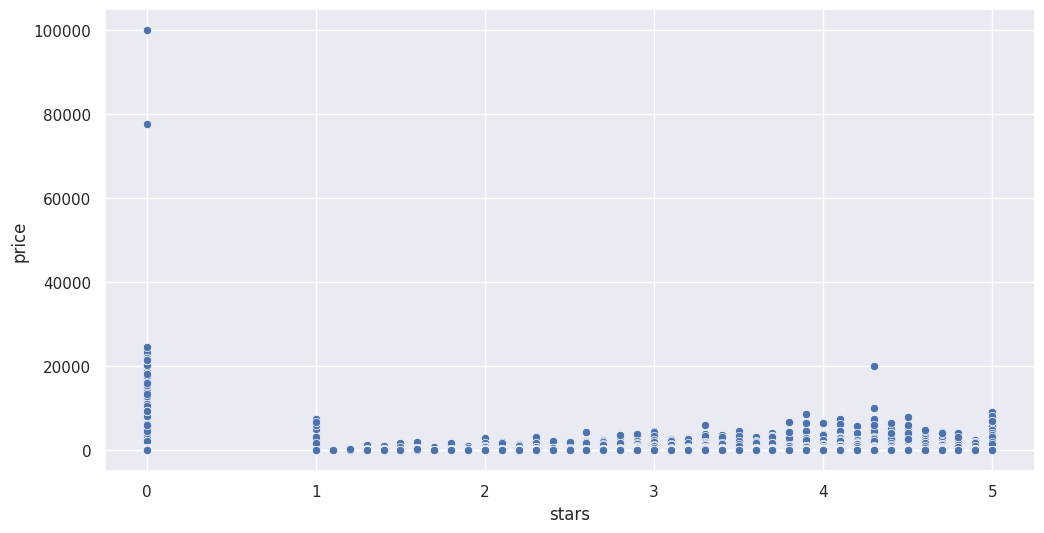

In [97]:
sns.scatterplot(x=aws_products.stars, y=aws_products.price)

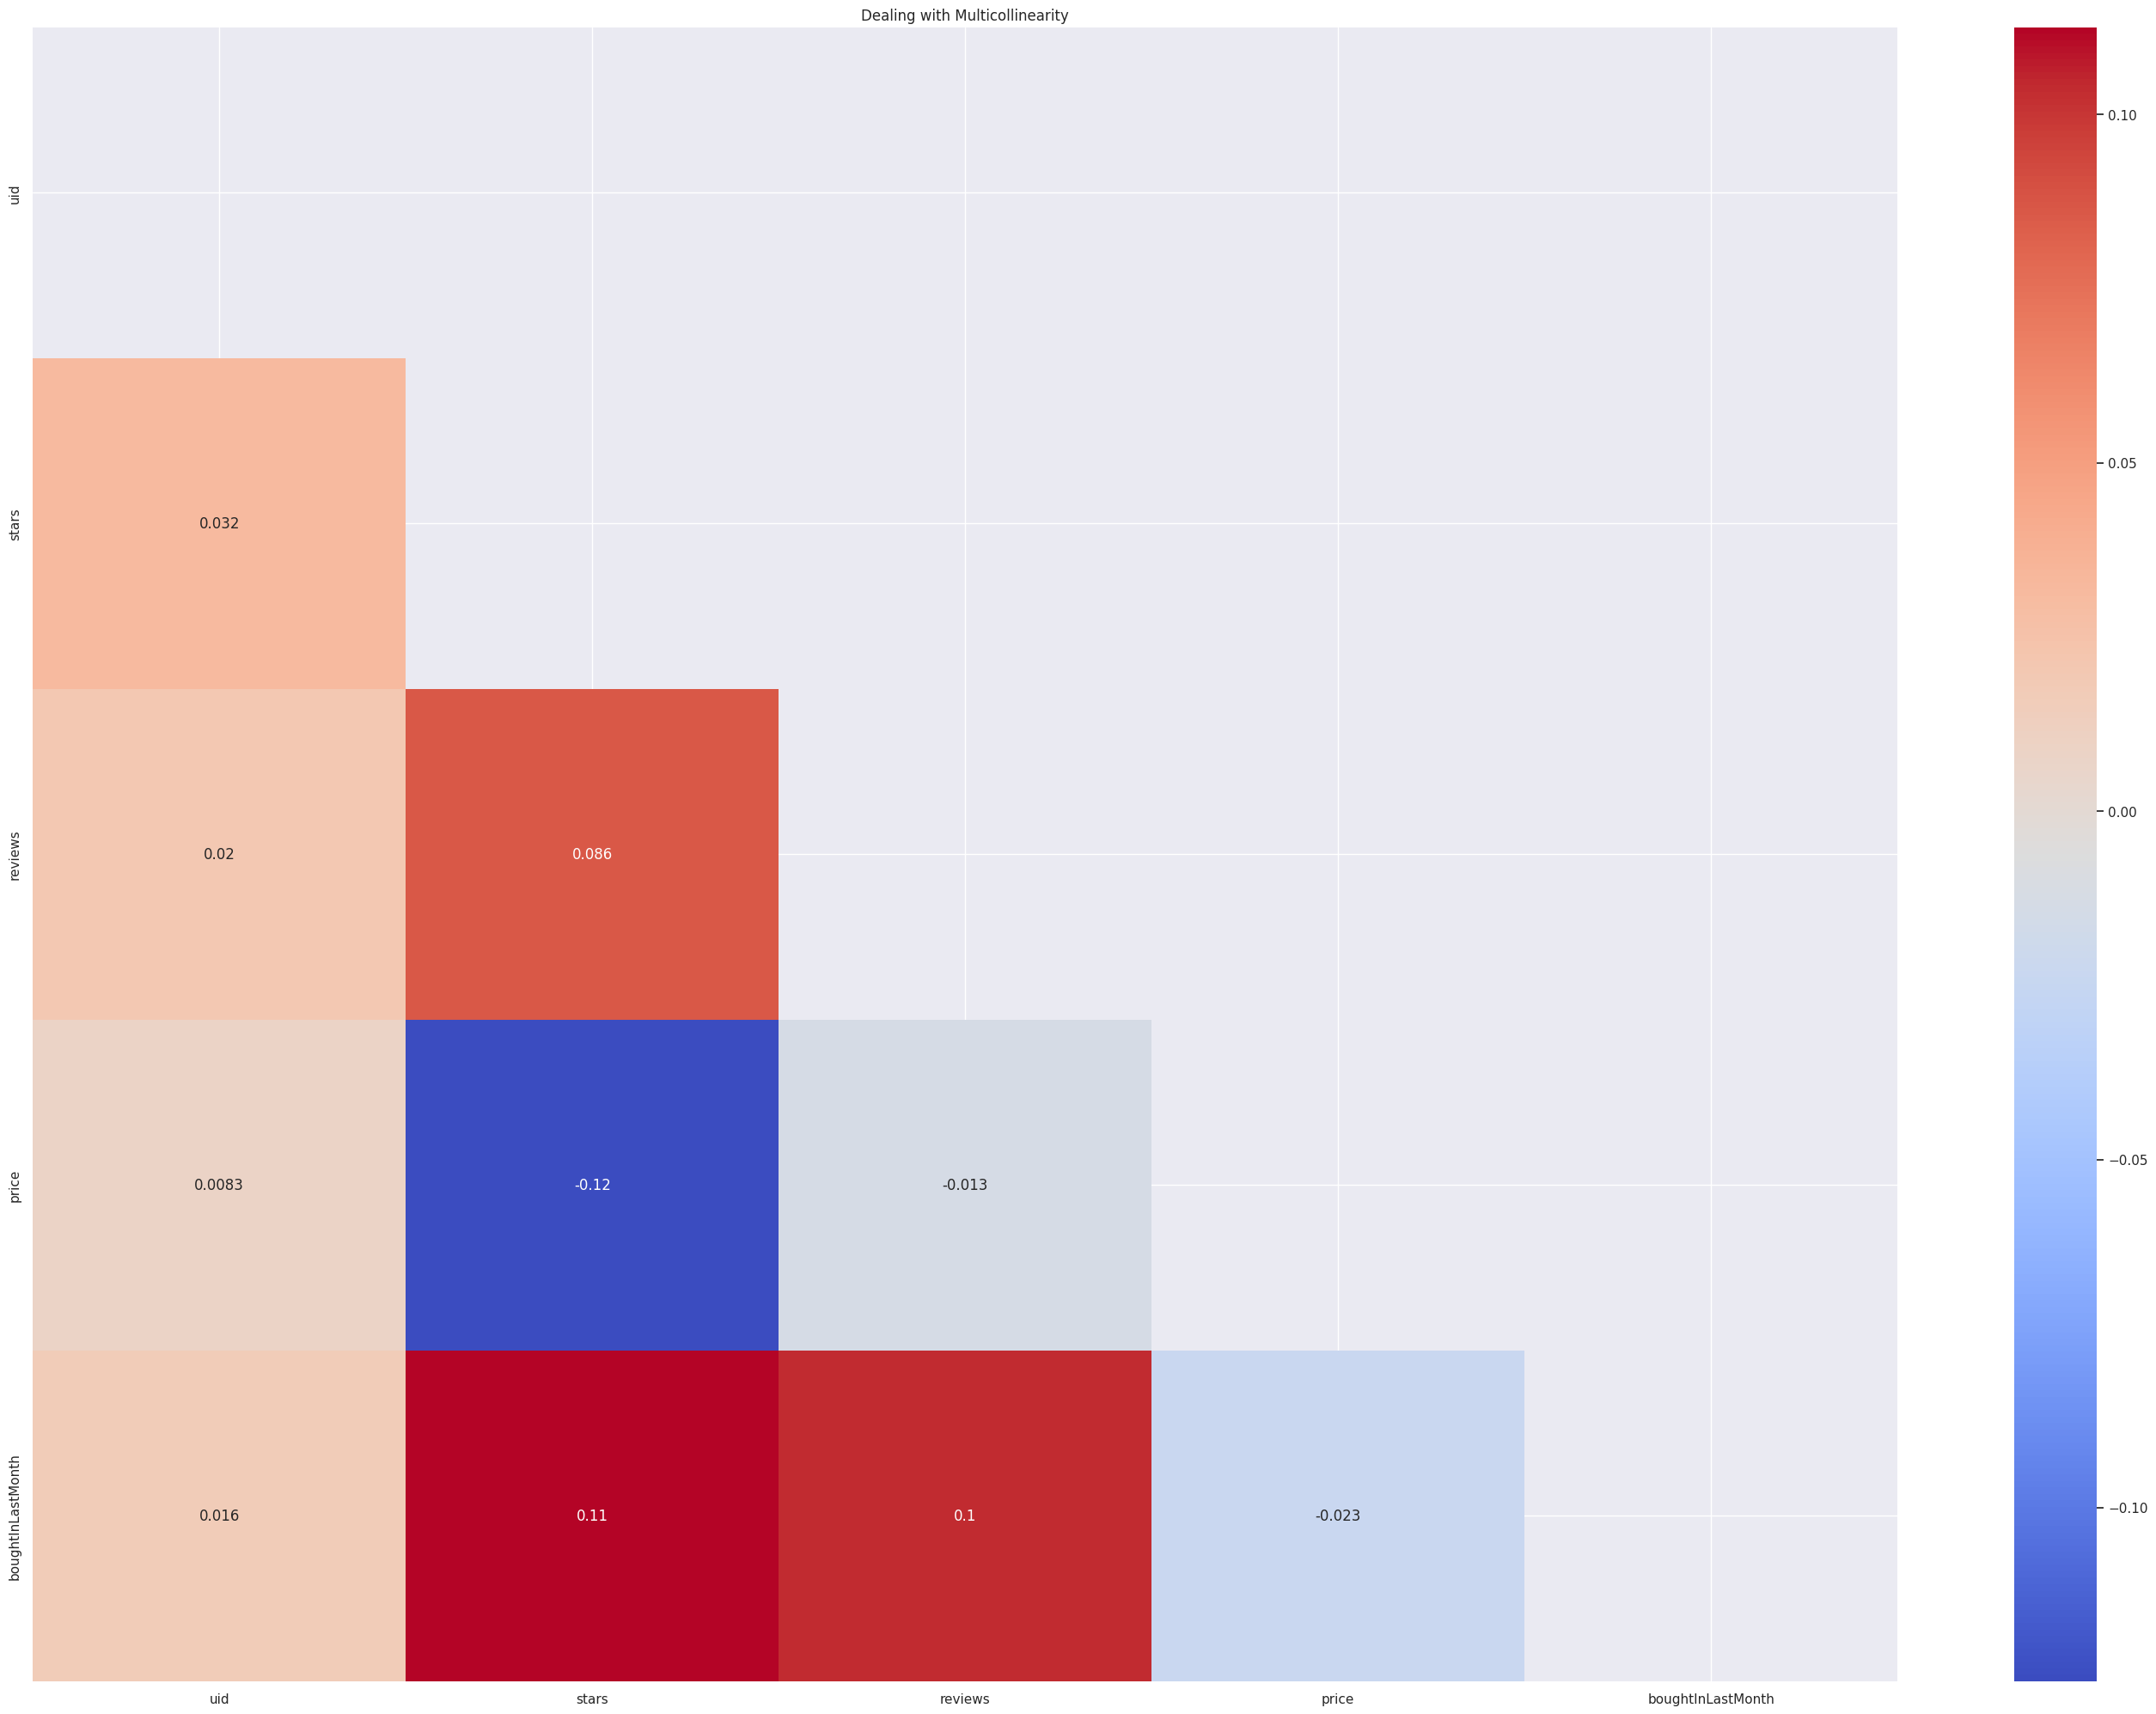

In [98]:
correlation_matrix = num.corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(35, 25))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Dealing with Multicollinearity")
plt.show()